# Module 3: Classification using Artificial Neural Networks

<i>Instructor: Zahra Sadeghi</i>

# Lecture

<!--<iframe width="640" height="360" src="YOUTUBE EMBED LINK" title="YouTube video player" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" referrerpolicy="strict-origin-when-cross-origin" allowfullscreen></iframe>
-->

<!--<iframe src="GOOGLE SLIDES LINK/preview" width="640" height="480" allow="autoplay"></iframe>  
-->

# Lab


## Example 1

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


### Create the Dataset

In [ ]:
X, y = make_moons(
    n_samples=500,
    noise=0.2,
    random_state=42 # controls the randomness, allowing you to reproduce experiments and obtain consistent results when you run the same code under the same conditions.
)

In [ ]:
print(X[:10])

In [ ]:
print(y[:10])

### Visualize the data

We have a binary classification problem with two nonlinear classes. Our goal is to learn a decision boundary that separates them.

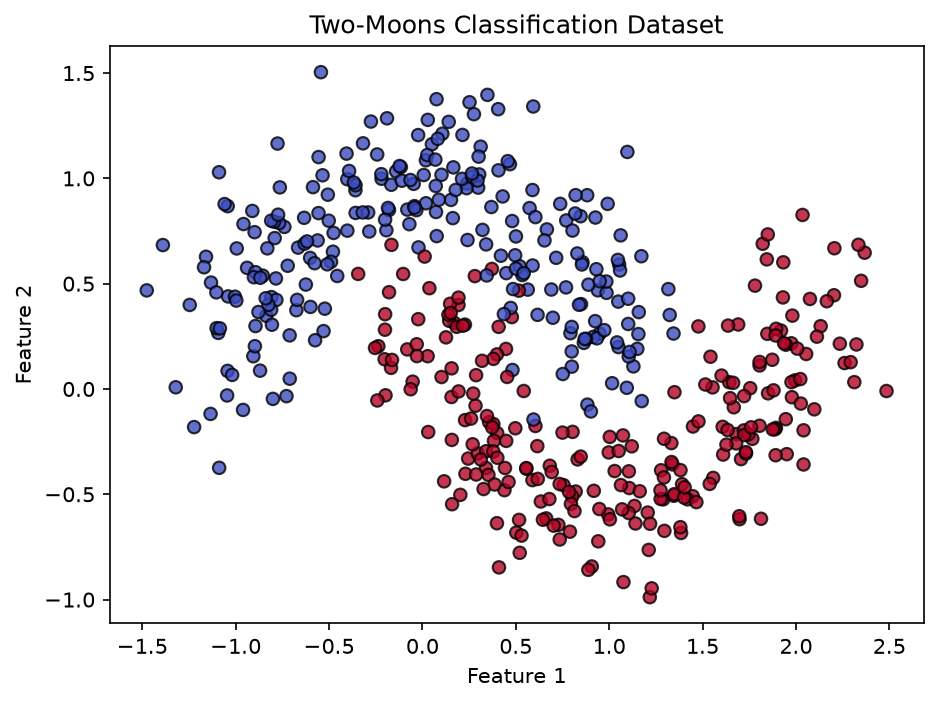

In [9]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolor="k",
    alpha=0.8
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two-Moons Classification Dataset")

plt.show()

4. Create the K-Fold Cross-Validation strategy: "We divide the data into five folds. In each iteration, four folds are used for training and one fold is used for validation."

In [10]:
# stratification does not balance the dataset. It preserves approximately the original class proportions.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


### Define a baseline MLP

With solver="sgd", scikit-learn uses mini-batch gradient-based optimization by default. The default batch_size is "auto", which means: min(200, n_samples)

In [12]:
mlp = MLPClassifier(
    hidden_layer_sizes=(10, 10),
    activation="relu",
    solver="sgd",
    alpha=0.0001, # L2 Regularization strength
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=42
)


### Create a Pipeline

The Pipeline ensures that preprocessing and model training happen together. During K-Fold Cross-Validation, the scaler is fitted only on the training portion of each fold, preventing data leakage."

StandardScaler standardizes each input feature so that it has approximately:

    Mean = 0
    Standard deviation = 1

    z=(x−μ)/σ

In [13]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", mlp)
])

Create the train/test split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

Perform 5-Fold Cross-Validation

In [16]:
np.shape(X),np.shape(X_train),np.shape(X_test)

((500, 2), (400, 2), (100, 2))

In [17]:
scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("CV F1 scores:", scores)

print("\nMean accuracy:")
print(scores.mean())

print("\nStandard deviation:")
print(scores.std())


CV F1 scores: [0.85333333 0.85333333 0.89411765 0.88888889 0.875     ]

Mean accuracy:
0.8729346405228758

Standard deviation:
0.017181071000806653


This MLP works reasonably well. But are these hyperparameters optimal?

### Grid Search

Grid Search with 5-Fold CV. GridSearchCV asks: "Which combination of hyperparameters gives me the best cross-validated F1 score?"

| hidden_layer_sizes | Number of hidden layers | Heurons in each hidden layer |
|:----|----:|:----|
| (5,) | 1 | 5 |
| (10,) | 1 | 10 |
| (10, 10) | 2 | 10, 10 |
| (20, 10) | 2 | 20, 10 |

In [18]:
param_grid = {
    "mlp__hidden_layer_sizes": [
        (5,),
        (10,),
        (10, 10),
        (20, 10)
    ],

    "mlp__alpha": [
        0.0001,
        0.001,
        0.01
    ], #L2 regularization strength

    "mlp__learning_rate_init": [
        0.001,
        0.01
    ]
}


In [19]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    model,
    param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1 #use all available CPU cores
)


In [20]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lver='sgd'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'mlp__alpha': [0.0001, 0.001, ...], 'mlp__hidden_layer_sizes': [(5,), (10,), ...], 'mlp__learning_rate_init': [0.001, 0.01]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for

GridSearchCV already trained using best parameters

In [21]:
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV F1-score:") #mean cross-validation score for the best-performing hyperparameter combination
print(grid_search.best_score_)


Best parameters:
{'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (10, 10), 'mlp__learning_rate_init': 0.01}

Best CV F1-score:
0.9824018776972363


In [22]:
from sklearn.metrics import accuracy_score, classification_report
best_model = grid_search.best_estimator_

y_test_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_test_pred)

print("Best MLP Model:")
print(best_model)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nTest Accuracy:", accuracy)




Best MLP Model:
Pipeline(steps=[('scaler', StandardScaler()),
                ('mlp',
                 MLPClassifier(hidden_layer_sizes=(10, 10),
                               learning_rate_init=0.01, max_iter=1000,
                               random_state=42, solver='sgd'))])

Best Parameters:
{'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (10, 10), 'mlp__learning_rate_init': 0.01}

Test Accuracy: 0.98


Visualize the decision boundary

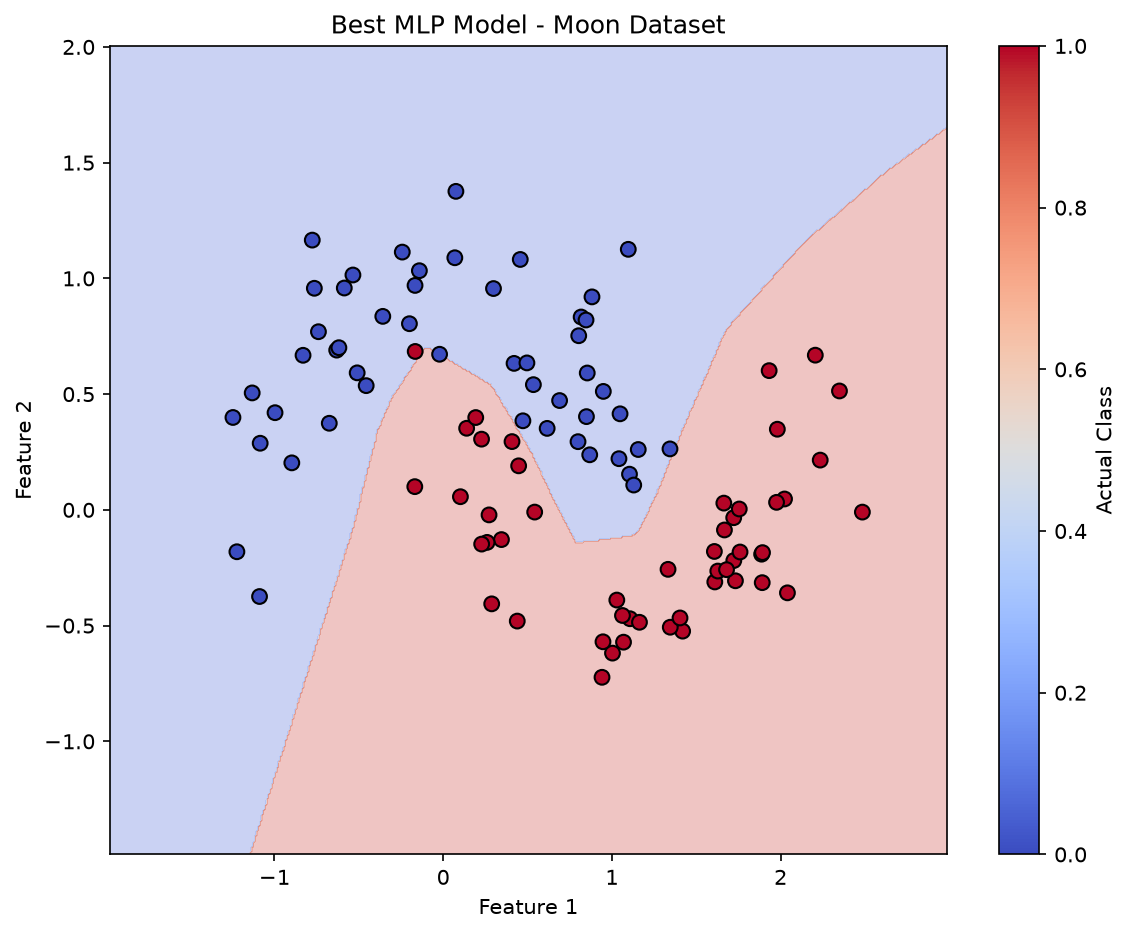

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Best model selected by GridSearchCV
best_model = grid_search.best_estimator_

# Create a mesh/grid covering the dataset
x_min = X[:, 0].min() - 0.5
x_max = X[:, 0].max() + 0.5
y_min = X[:, 1].min() - 0.5
y_max = X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Predict the class for every point in the grid
grid_points = np.c_[xx.ravel(), yy.ravel()] #number of points × number of features

Z = best_model.predict(grid_points)
Z = Z.reshape(xx.shape)

# --------------------------------------------------
# Plot
# --------------------------------------------------
plt.figure(figsize=(9, 7))

# Decision boundary: color regions according to the model's predictions.
plt.contourf(
    xx,
    yy,
    Z,
    cmap="coolwarm",
    alpha=0.3
)

# Test data
scatter = plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    cmap="coolwarm",
    edgecolors="black",
    s=50
)

plt.title("Best MLP Model - Moon Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.colorbar(scatter, label="Actual Class")

plt.show()


## Example 2

In [24]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

### Generate the Dataset

In [25]:
X, y = make_moons(
    n_samples=300,
    noise=0.20,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


### Visualize the Original Data

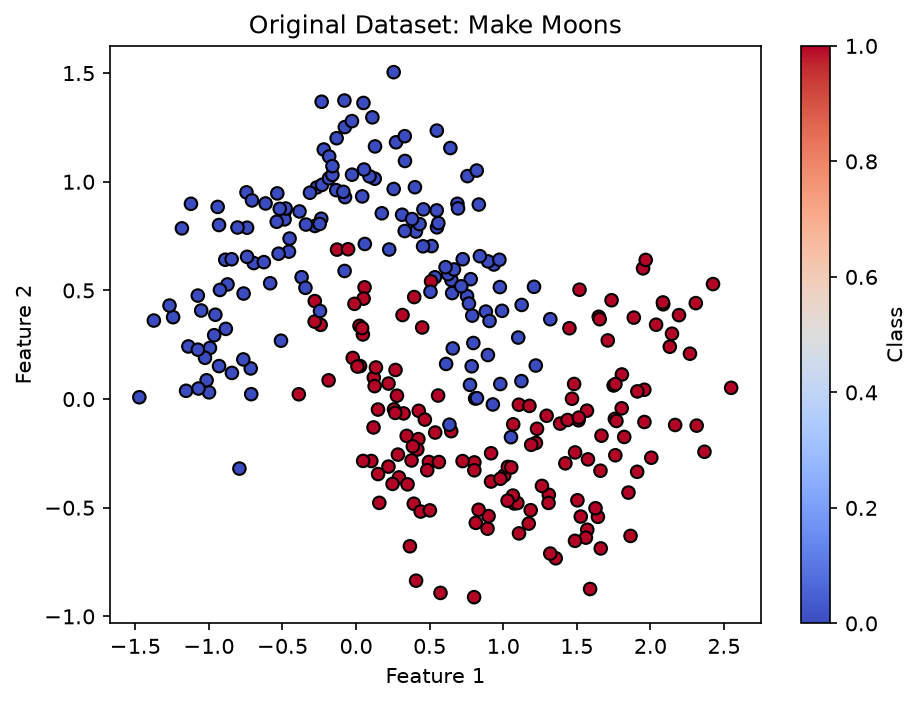

In [26]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original Dataset: Make Moons")
plt.colorbar(label="Class")
plt.show()

### Train MLP with Different Learning Rates

In [27]:
learning_rates = [0.001, 0.01, 0.1]

models = {}
losses = {}

for lr in learning_rates:

    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(10, 10),
            activation="relu",
            solver="adam",
            learning_rate_init=lr,
            max_iter=1000,
            random_state=42
        )
    )

    model.fit(X_train, y_train)

    # Access the trained MLP inside the pipeline
    mlp = model.named_steps["mlpclassifier"]

    models[lr] = model
    losses[lr] = mlp.loss_curve_

    predictions = model.predict(X_test)

    print(f"Learning rate: {lr}")
    print(f"Test accuracy: {accuracy_score(y_test, predictions):.3f}")
    print(f"Training iterations: {mlp.n_iter_}")
    print("-" * 35)

Learning rate: 0.001
Test accuracy: 0.917
Training iterations: 830
-----------------------------------
Learning rate: 0.01
Test accuracy: 0.900
Training iterations: 197
-----------------------------------
Learning rate: 0.1
Test accuracy: 0.883
Training iterations: 78
-----------------------------------


### Visualize Training Loss

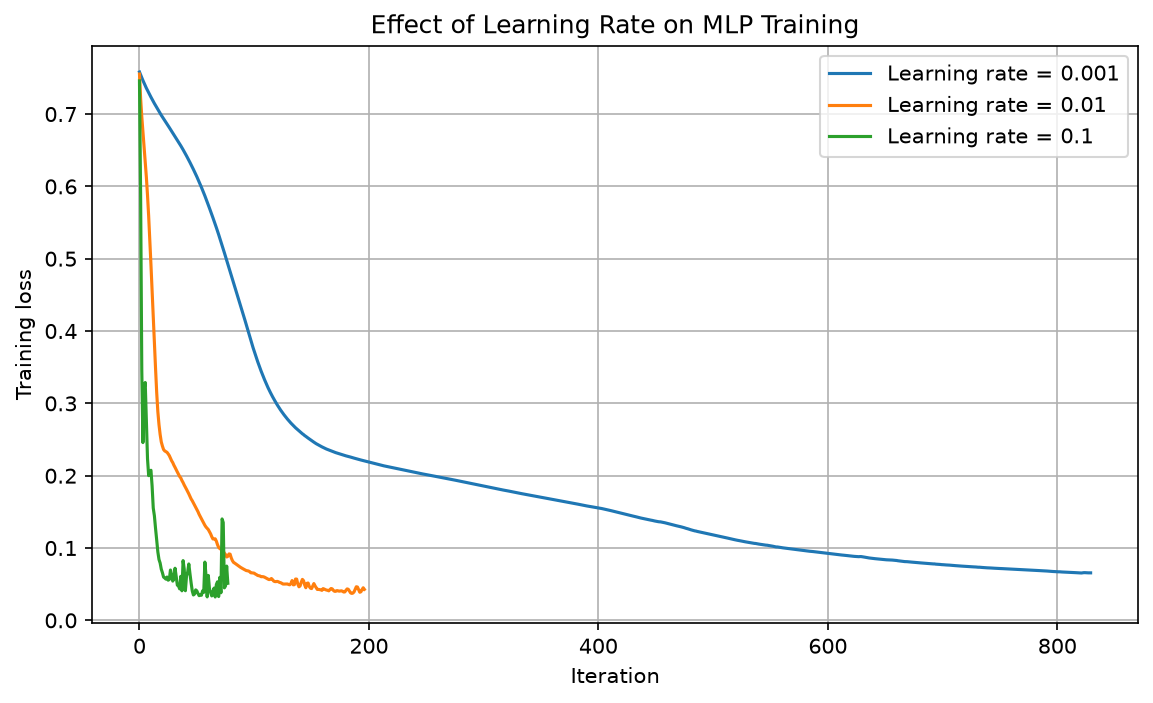

In [28]:
plt.figure(figsize=(9, 5))

for lr in learning_rates:
    plt.plot(
        losses[lr],
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.title("Effect of Learning Rate on MLP Training")
plt.legend()
plt.grid(True)
plt.show()

### Visualize Decision Boundaries

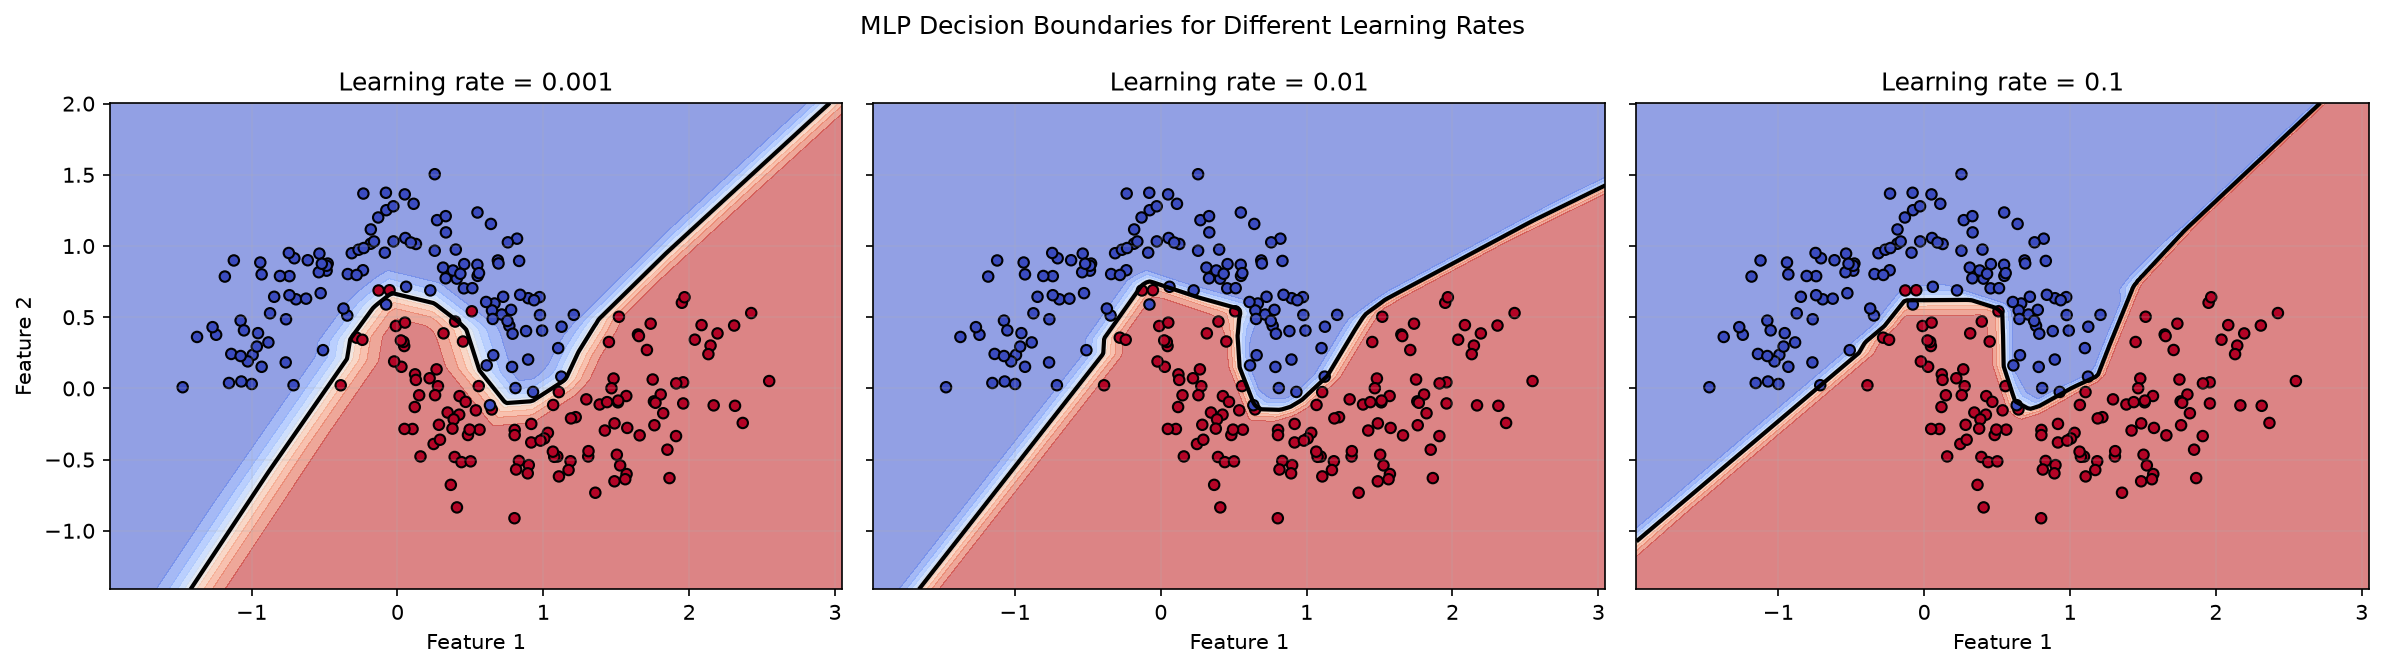

In [29]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5),
    sharex=True,
    sharey=True
)

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]

for ax, lr in zip(axes, learning_rates):

    model = models[lr]

    probabilities = model.predict_proba(grid)[:, 1]
    Z = probabilities.reshape(xx.shape)

    # Predicted probability regions
    ax.contourf(
        xx, yy, Z,
        levels=np.linspace(0, 1, 11),
        cmap="coolwarm",
        alpha=0.6
    )

    # Decision boundary at probability 0.5
    ax.contour(
        xx, yy, Z,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    # Training data
    ax.scatter(
        X_train[:, 0],
        X_train[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    ax.set_title(f"Learning rate = {lr}")
    ax.set_xlabel("Feature 1")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Feature 2")

fig.suptitle("MLP Decision Boundaries for Different Learning Rates")
plt.tight_layout()
plt.show()

* Learning rate = 0.001: Updates may be small, leading to slower learning.
* Learning rate = 0.01: May provide a good balance between speed and stability.
* Learning rate = 0.1: Updates are larger, which may speed up learning or make it less stable.

## Example 3

In [30]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

In [31]:
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Full-batch Gradient Descent

In [32]:
batch_size = len(X_train)

One subtle point: in scikit-learn's implementation, the output activation is handled internally according to the classification task.
activation="relu" only specifies the hidden layers.

In [33]:
mlp_full = MLPClassifier(
    hidden_layer_sizes=(20, 20),
    activation="relu",
    solver="sgd",
    learning_rate_init=0.01,
    batch_size=len(X_train),   # Full batch
    max_iter=100,
    random_state=42
)

mlp_full.fit(X_train, y_train)

C:\Users\benfi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(20, ...)"
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'sgd'
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",800
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.01
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",100
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


### Stochastic Gradient Descent

In [34]:
batch_size = 1

mlp_sgd = MLPClassifier(
    hidden_layer_sizes=(20, 20),
    activation="relu",
    solver="sgd",
    learning_rate_init=0.01,
    batch_size=1,              # stochastic GD: batch_size=1
    max_iter=100,              # max_iter is the maximum number of epochs
    random_state=42
)

mlp_sgd.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(20, ...)"
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'sgd'
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",1
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.01
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",100
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


### Mini-batch Gradient Descent

In [35]:
batch_size = 32

mlp_mini = MLPClassifier(
    hidden_layer_sizes=(20, 20),
    activation="relu",
    solver="sgd",
    learning_rate_init=0.01,
    batch_size=32,             # Mini-batch
    max_iter=100,
    random_state=42
)

mlp_mini.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(20, ...)"
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'sgd'
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",32
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.01
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",100
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


### Compare the Loss Curves

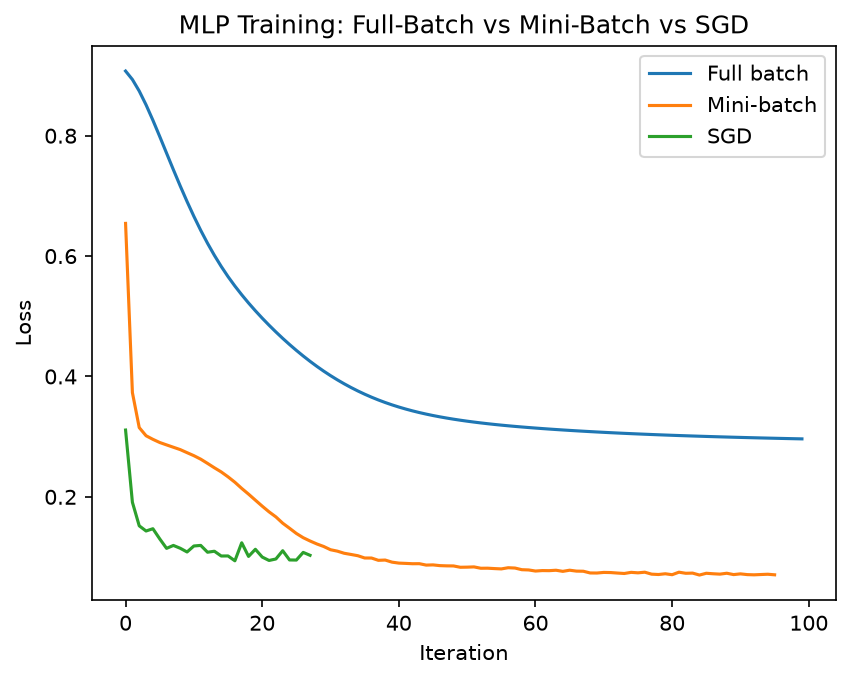

In [36]:
plt.plot(mlp_full.loss_curve_, label="Full batch")
plt.plot(mlp_mini.loss_curve_, label="Mini-batch")
plt.plot(mlp_sgd.loss_curve_, label="SGD")

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.title("MLP Training: Full-Batch vs Mini-Batch vs SGD")
plt.show()

## Example 4

In [64]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

np.random.seed(42)


### Create artificial moon data

In [38]:
X, y = make_moons(
    n_samples=1000,
    noise=0.25,
    random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("First 5 observations:")
print(X[:5])

print("First 5 labels:")
print(y[:5])


X shape: (1000, 2)
y shape: (1000,)
First 5 observations:
[[-0.14176498  0.55823629]
 [ 1.19796627 -0.30399544]
 [ 0.759391    0.1102501 ]
 [ 0.02331452 -0.60356298]
 [-0.80797972  0.54846574]]
First 5 labels:
[1 1 1 1 0]


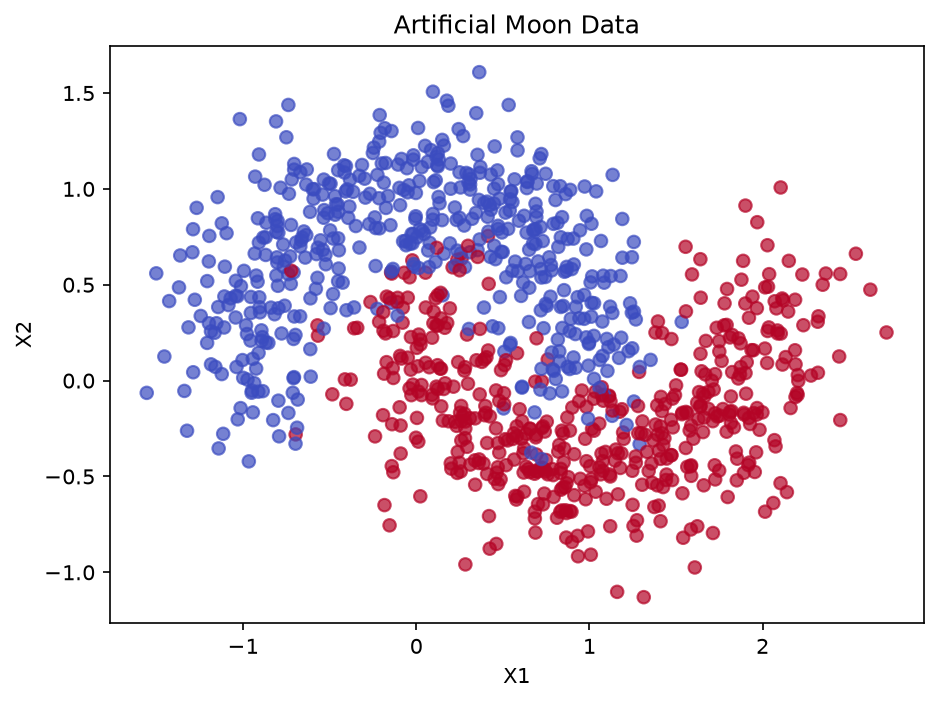

In [39]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    alpha=0.7
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Artificial Moon Data")
plt.show()


train_test_split(X, y, test_size=0.15, stratify=y)
Purpose: Preserves approximately the same proportion of each class in the training and test sets.

For example, if your target variable contains 80% No and 20% Yes, both datasets will have approximately the same proportions.

Use when: You are working on a classification problem, especially with imbalanced classes.

In [41]:
#  split your dataset into two parts: a temporary dataset for training/validation and a test dataset for final evaluation.
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15, #Allocates 15% of the data to the test set and 85% to the temporary set.
    stratify=y,  #Preserves approximately the same class proportions in both sets as in the original dataset.
    random_state=42
)


groups = df['region']

stratify = groups #Preserves proportions of another categorical variable

This approach is useful when you want to maintain the distribution of another categorical variable, such as region or demographic category.

Now split the remaining 85% into training and validation.

Entire dataset (100%) : x_tem (85%), x_test (15%)

In [42]:
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.1765,   # Allocates approximately 17.65% of the temporary dataset to validation.
    stratify=y_temp,   # Preserves approximately the same class proportions in the training and validation sets.
    random_state=42
)


In [43]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (699, 2)
Validation: (151, 2)
Test: (150, 2)


The class proportions should be approximately the same because of stratify.

Class proportion = (Number of samples in the class) / (Total number of samples)

In [44]:
print("Overall class proportions:")
print(np.bincount(y) / len(y)) #np.bincount() counts how many times each non-negative integer appears in an array.

print("\nTraining class proportions:")
print(np.bincount(y_train) / len(y_train))

print("\nValidation class proportions:")
print(np.bincount(y_val) / len(y_val))

print("\nTest class proportions:")
print(np.bincount(y_test) / len(y_test))


Overall class proportions:
[0.5 0.5]

Training class proportions:
[0.49928469 0.50071531]

Validation class proportions:
[0.50331126 0.49668874]

Test class proportions:
[0.5 0.5]


In [45]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)


In [ ]:
ann = MLPClassifier(
    hidden_layer_sizes=(10,), #  Hidden Layer (10 neurons)
    activation="relu",
    solver="sgd",
    max_iter=1000,
    random_state=42
)

ann.fit() — Training the model

During training, the ANN:

Takes the input features from X_train.
Makes predictions.
Compares its predictions with the actual labels in y_train.
Calculates the error (loss).
Adjusts its weights to reduce that error.
Repeats this process over multiple training iterations.

In [47]:
ann.fit(X_train_scaled, y_train)


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10,)"
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'sgd'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


 ann.predict() — Making predictions

The purpose of predict() is to use the trained model to predict the target labels for the input data.

X_test: The input features for the test dataset.
y_pred: The labels predicted by the ANN.
Unlike fit(), predict() does not train the model or adjust its weights.

In [48]:
y_train_pred = ann.predict(X_train_scaled)

train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

print("Training accuracy:", train_accuracy)


Training accuracy: 0.8497854077253219


In [49]:
y_val_pred = ann.predict(X_val_scaled)

val_accuracy = accuracy_score(
    y_val,
    y_val_pred
)

print("Validation accuracy:", val_accuracy)


Validation accuracy: 0.847682119205298


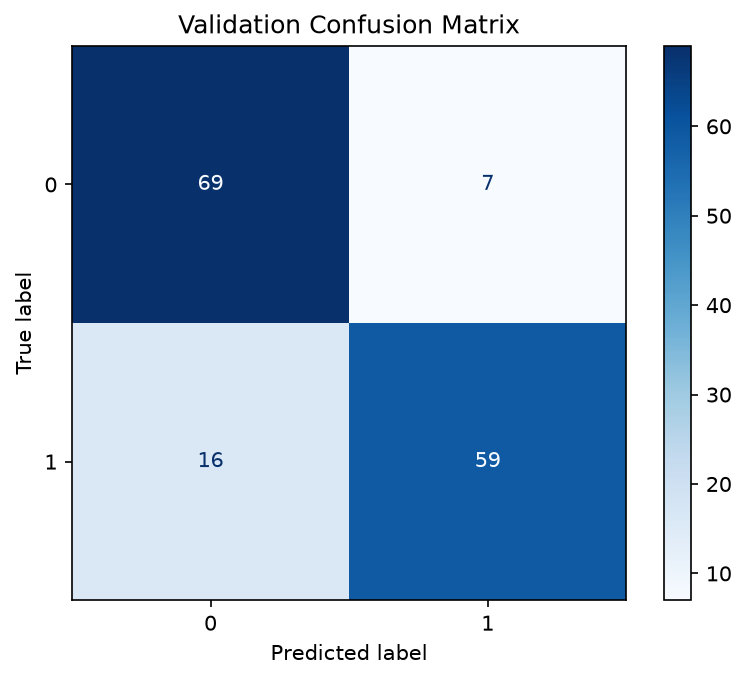

In [52]:
cm = confusion_matrix(
    y_val,
    y_val_pred
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    cmap="Blues"
)

plt.title("Validation Confusion Matrix")
plt.show()

Macro F1-score measures a classification model's performance across all classes, giving each class equal importance regardless of how many samples it contains.

![Macro F1 Formula](img\macro-f1.png)


K = number of classes.
F1i = F1-score for class i.

![Weighted F1 Formula](img\weighted-f1.png)

Weighted F1 calculates the F1-score for each class and weights it according to the number of actual samples in that class.

K = number of classes.
ni = number of actual samples in class i.
F1i = F1-score for class i.

In [53]:
print(
    classification_report(
        y_val,
        y_val_pred
    )
)


              precision    recall  f1-score   support

           0       0.81      0.91      0.86        76
           1       0.89      0.79      0.84        75

    accuracy                           0.85       151
   macro avg       0.85      0.85      0.85       151
weighted avg       0.85      0.85      0.85       151



In [54]:
y_val_prob = ann.predict_proba(X_val_scaled)[:, 1] #calculates the predicted probability that each observation in your validation set belongs to class 1.

print(y_val_prob[:10])


[0.18488174 0.82853905 0.99079311 0.14011839 0.15506694 0.05794431 0.14837578 0.09468278 0.94824168 0.06680027]


In [60]:
val_auc = roc_auc_score(
    y_val,
    y_val_prob
)

print("Validation ROC-AUC:", val_auc)


Validation ROC-AUC: 0.9515789473684211


cross-validation: Our validation set gives us one estimate of performance.

But that estimate can depend somewhat on how we happened to split the data.

5-fold stratified cross-validation:

Fold 1:  TRAIN TRAIN TRAIN VALID
Fold 2:  TRAIN TRAIN VALID TRAIN
Fold 3:  TRAIN VALID TRAIN TRAIN
Fold 4:  VALID TRAIN TRAIN TRAIN
Fold 5:  TRAIN TRAIN TRAIN VALID


In [61]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ann", MLPClassifier(
        hidden_layer_sizes=(10,),
        activation="relu", #hidden layer --- For scikit-learn's MLPClassifier, the output activation is selected automatically. binary: sigmoid, multiclass: softmax
        solver="adam",
        max_iter=1000,
        random_state=42
    ))
])


In [57]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [62]:
cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    return_train_score=True
)

cv_results

C:\Users\benfi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\benfi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


{'fit_time': array([0.94594765, 0.29873848, 0.70774269, 0.17882371, 0.26772141]),
 'score_time': array([0.01406431, 0.01017118, 0.0081439 , 0.01793575, 0.00652456]),
 'test_accuracy': array([0.94285714, 0.86428571, 0.96428571, 0.85714286, 0.81294964]),
 'train_accuracy': array([0.93381038, 0.86404293, 0.9391771 , 0.86404293, 0.87321429]),
 'test_precision': array([0.95588235, 0.88059701, 0.97101449, 0.83783784, 0.76829268]),
 'train_precision': array([0.93862816, 0.85172414, 0.93006993, 0.85664336, 0.85910653]),
 'test_recall': array([0.92857143, 0.84285714, 0.95714286, 0.88571429, 0.9       ]),
 'train_recall': array([0.92857143, 0.88214286, 0.95      , 0.875     , 0.89285714]),
 'test_f1': array([0.94202899, 0.86131387, 0.96402878, 0.86111111, 0.82894737]),
 'train_f1': array([0.93357271, 0.86666667, 0.93992933, 0.86572438, 0.87565674]),
 'test_roc_auc': array([0.98591837, 0.9444898 , 0.99244898, 0.92979592, 0.90848861]),
 'train_roc_auc': array([0.97901946, 0.94098822, 0.97844342, 0

In [63]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:

    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric:10s}: "
        f"{scores.mean():.3f} "
        f"+/- {scores.std():.3f}"
    )


accuracy  : 0.888 +/- 0.057
precision : 0.883 +/- 0.075
recall    : 0.903 +/- 0.039
f1        : 0.891 +/- 0.052
roc_auc   : 0.952 +/- 0.032
